# Parkinson’s Disease: Exploratory Analysis of Voice Measurements

**Portfolio project | Python · pandas · seaborn · matplotlib**

## Research question
What patterns and linear associations are visible between recorded voice measurements and Parkinson’s symptom scores (`motor_UPDRS` and `total_UPDRS`) in the provided 100-row sample?

**Scope:** Descriptive exploratory data analysis (EDA), not a diagnostic or predictive model. Correlation does not imply causation.

## 1. Dataset and reproducibility

This project uses the supplied `parkinsons_sample.csv` (100 records, 22 columns). It contains participant identifiers, age, sex, time, symptom scores, and voice-related measurements. It appears consistent in structure with the UCI Parkinsons Telemonitoring dataset; **the sampling method and exact provenance of this 100-row subset have not been verified**. Results apply only to this supplied subset.

Place `parkinsons_sample.csv` alongside this notebook and run all cells from top to bottom. The notebook uses common packages available in Google Colab.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
DATA_FILE = Path("parkinsons_sample.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Upload parkinsons_sample.csv to the Colab Files panel, or put it beside this notebook.")
df = pd.read_csv(DATA_FILE)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
display(df.head())

Loaded 100 rows and 22 columns


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,39,48,1,198.891493,15.530010,34.475628,0.017657,0.000141,0.006100,0.008391,0.010552,0.070293,0.773084,0.016284,0.018327,0.029614,0.016116,0.076940,13.835649,0.427289,0.549886,0.324797
1,29,47,0,35.185051,12.426189,34.790770,0.011480,0.000107,0.007963,0.003388,0.023283,0.013975,0.131379,0.024952,0.023731,0.004566,0.024849,0.142489,14.235107,0.324785,0.654150,0.238368
2,15,51,0,3.615073,22.849434,22.498532,0.004132,0.000040,0.001156,0.003183,0.011074,0.062944,0.905429,0.009653,0.014946,0.007703,0.013495,0.065194,19.692032,0.454397,0.757346,0.226076
3,8,73,1,98.778743,30.654997,22.751124,0.008814,0.000082,0.008522,0.002351,0.025874,0.099942,0.874114,0.025358,0.002182,0.002499,0.027005,0.025178,25.085071,0.569670,0.812160,0.408743
4,21,72,1,35.764542,11.745808,38.073228,0.015774,0.000010,0.007485,0.006118,0.006819,0.060023,0.511689,0.023412,0.005756,0.019560,0.003067,0.119758,22.389955,0.534745,0.586884,0.134570


## 2. Data quality and summary statistics
Check data types, missing values, duplicate records, and numerical distributions before drawing conclusions.

In [2]:
print("Column types:")
display(df.dtypes.rename("dtype").to_frame())
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df.describe().T.round(3))

Column types:


,dtype
subject#,int64
age,int64
sex,int64
test_time,float64
motor_UPDRS,float64
total_UPDRS,float64
Jitter(%),float64
Jitter(Abs),float64
Jitter:RAP,float64
Jitter:PPQ5,float64


Missing values: 0
Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
subject#,100.0,20.910,12.219,1.000,9.750,21.000,29.250,42.000
age,100.0,60.410,12.605,40.000,48.000,63.000,71.000,79.000
sex,100.0,0.550,0.500,0.000,0.000,1.000,1.000,1.000
test_time,100.0,95.530,57.631,1.037,50.668,87.287,142.066,198.910
motor_UPDRS,100.0,24.808,8.623,10.459,17.424,25.266,30.688,39.385
total_UPDRS,100.0,35.160,8.738,20.969,27.605,34.391,42.253,49.878
Jitter(%),100.0,0.011,0.005,0.001,0.007,0.011,0.015,0.020
Jitter(Abs),100.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Jitter:RAP,100.0,0.005,0.003,0.000,0.003,0.006,0.008,0.010
Jitter:PPQ5,100.0,0.005,0.003,0.000,0.003,0.005,0.008,0.010


### Potential outliers (IQR rule)
The interquartile-range rule flags extreme values for inspection; **we do not automatically remove them**, because unusual biomedical measurements may be meaningful. `subject#` is an identifier and is excluded from this check.

In [3]:
numeric = df.select_dtypes(include="number")
measurements = numeric.drop(columns=["subject#"], errors="ignore")
q1, q3 = measurements.quantile(.25), measurements.quantile(.75)
iqr = q3 - q1
outlier_counts = ((measurements.lt(q1 - 1.5 * iqr)) | (measurements.gt(q3 + 1.5 * iqr))).sum()
display(outlier_counts.sort_values(ascending=False).rename("IQR-flagged values").to_frame().head(12))

,IQR-flagged values
age,0
sex,0
test_time,0
motor_UPDRS,0
total_UPDRS,0
Jitter(%),0
Jitter(Abs),0
Jitter:RAP,0
Jitter:PPQ5,0
Jitter:DDP,0


## 3. Symptom-score distributions
Inspect the spread and shape of both UPDRS scores in the sample.

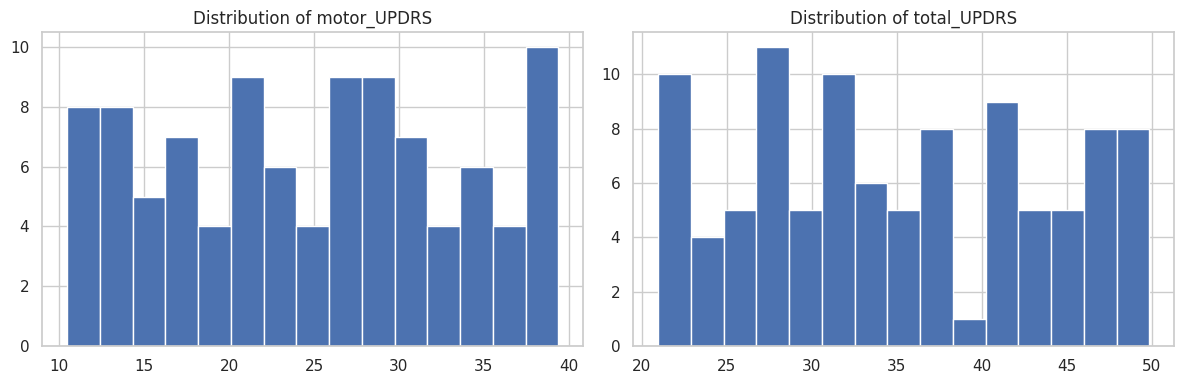

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, ["motor_UPDRS", "total_UPDRS"]):
    ax.hist(df[target].dropna(), bins=15, edgecolor="white")
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

## 4. Correlation analysis

Pearson correlation measures *linear* association and ranges from −1 to +1. We exclude `subject#` from the feature ranking because it is an identifier, and exclude `motor_UPDRS` when ranking voice measurements against `total_UPDRS` to avoid confusing the two outcomes with voice features.

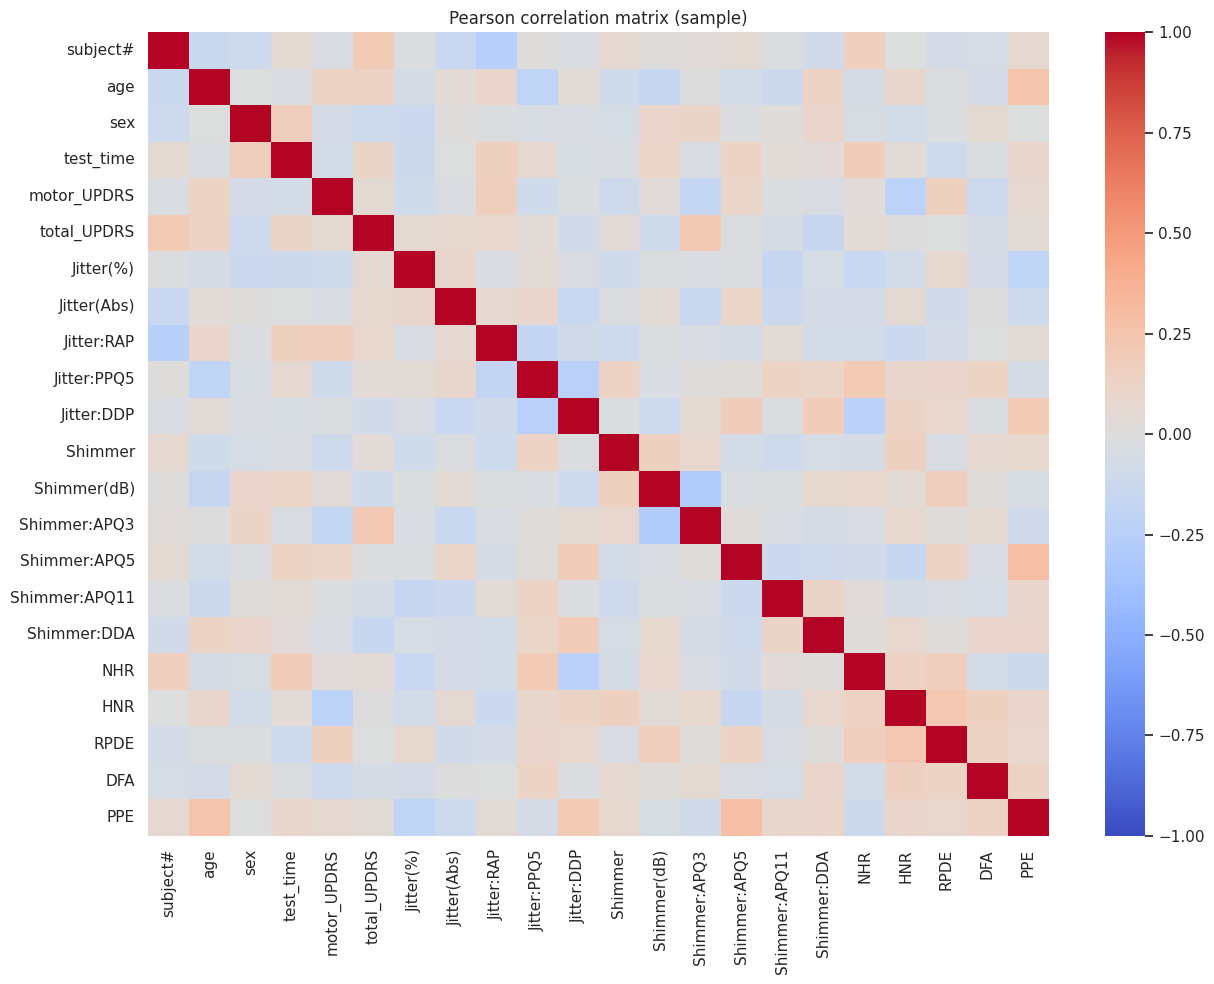

Voice-feature correlations with total_UPDRS (ranked by absolute value):


,Pearson r
Shimmer:APQ3,0.217
Shimmer:DDA,-0.154
Shimmer(dB),-0.101
Jitter:DDP,-0.087
Jitter:RAP,0.085
Jitter(Abs),0.071
Shimmer:APQ11,-0.060
Jitter(%),0.059
DFA,-0.055
PPE,0.046


Highest absolute correlation: Shimmer:APQ3 (r=0.217)


In [5]:
corr = numeric.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlation matrix (sample)")
plt.tight_layout()
plt.show()
voice_cols = list(df.columns[df.columns.get_loc("Jitter(%)"):])
voice_corr = corr.loc[voice_cols, "total_UPDRS"].sort_values(key=lambda s: s.abs(), ascending=False)
print("Voice-feature correlations with total_UPDRS (ranked by absolute value):")
display(voice_corr.round(3).rename("Pearson r").to_frame())
print("Highest absolute correlation:", voice_corr.index[0], f"(r={voice_corr.iloc[0]:.3f})")

## 5. Inspect the strongest sample voice association
This visualization is descriptive; a single correlation in a small sample is not evidence of clinical usefulness.

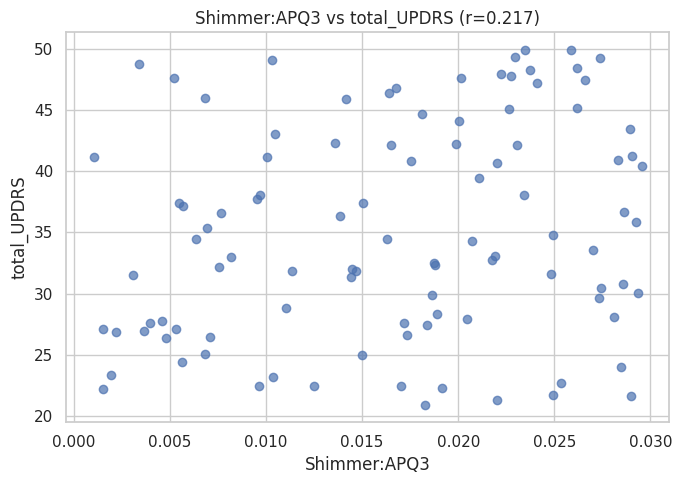

In [6]:
top_voice_feature = voice_corr.index[0]
plt.figure(figsize=(7, 5))
plt.scatter(df[top_voice_feature], df["total_UPDRS"], alpha=.7)
plt.xlabel(top_voice_feature)
plt.ylabel("total_UPDRS")
plt.title(f"{top_voice_feature} vs total_UPDRS (r={voice_corr.iloc[0]:.3f})")
plt.tight_layout()
plt.show()

## 6. Key findings

- The supplied sample has **100 observations and 22 columns**, with **no missing values**.
- Among the recorded **voice features**, `Shimmer:APQ3` has the largest absolute Pearson correlation with `total_UPDRS` in this sample (**r ≈ +0.217**), a **weak positive linear association**.
- These results **do not support a claim of strong predictive performance** or identify a clinically validated biomarker.
- The correlation heatmap and score distributions are useful exploratory summaries, but require further validation before modeling.

## 7. Limitations and next steps

- **Small, unverified subset:** The sampling procedure for this 100-row file is unknown, so results may not generalize.
- **Repeated measurements:** `subject#` and `test_time` suggest observations may be linked across individuals and time; we have not analyzed within-person trajectories. Future model evaluation should avoid subject-level data leakage.
- **Association is not causation:** Pearson correlation only measures linear relationships and can be sensitive to outliers.
- **Exploratory only:** No train/test split, predictive model, or clinical evaluation is performed here.

**Next steps:** verify dataset provenance, analyze repeated observations by subject, compare robust correlations, and—if appropriate—develop a subject-aware predictive baseline.

**Dataset reference for context:** [UCI Parkinsons Telemonitoring](https://archive.ics.uci.edu/dataset/189/parkinsons+telemonitoring). The link describes the broader dataset, not a verified source for this specific sample.